# First recovery step: anteroposterior / mediolateral decomposition of lateral steps

**Question.** When the first recovery step is a lateral step (UMS, LSS, UCS), where does the stepping foot land relative to where it started? The step vector is decomposed into the participant's anteroposterior (AP) and mediolateral (ML) axes and expressed in % of body height.

**Data.** DeCIMo open-source dataset (`data/DeCIMo_OpenSource_data`): 21 participants, 2 sensory conditions (NI / SI), 30 pushes each (1260 trials, 200 Hz).

**Method** (manuscript section numbers in brackets; code in `src/step_analysis/`):

1. *First recovery step* (§2.1.2.2). The first step found by the toe-speed step detector. **t_begin** and **t_end** are the inflexion points of the transversal toe speed around its peak (10 % of the maximum speed). The detection parameters are those of the previous analysis.
2. *Stepping strategy* (§2.3.1.1, Fig. 2.12). **Unified classification only**:
   - feet crossing → UCS;
   - the CoM crosses the front boundary of the base of support → FS;
   - otherwise, the first initial foot polygon entered by the CoM after t_begin decides: the non-stepping foot gives UMS, the stepping foot gives LSS;
   - none of the above → SCS.
3. *Step vector* (§2.3.1.2, Fig. 2.14). Horizontal displacement of the stepping toe marker between t_begin and t_end. Its origin is the origin of the plots.
4. *Reference frame.* The lab axes approximate the participant's axes: **ML = x (+ right), AP = y (+ forward)**. Participants were asked to align with these axes. `02_Analysis_Test.ipynb` checks this approximation at perturbation onset and finds it acceptable.
5. *Normalisation.* Each component is divided by the participant's standing height (`Anatomical_Info.csv`) and multiplied by 100.
6. *Perturbation descriptors* (Figures 3 to 5). The estimated perturbation angle is the direction of the CoM velocity at the moment of minimal time to boundary (§2.3.1.2). The perturbation intensity is the peak force of the push sensor.

**Two views of the same data.**
- **Anatomical frame**: + ML = participant's right.
- **Stepping-leg frame**: the ML sign is flipped for left-foot steps, so + ML is the lateral side of the stepping leg and − ML points towards the other foot (medial).

**Validation.** See `02_Analysis_Test.ipynb`:
- On the same input files, the pipeline reproduces the previous results (`AllQtyDF.csv`) in 100 % of the trials.
- The open data differ from the files used before in 26 trials. Within the strategies studied here, this changes only one trial: a UCS that becomes a leg abduction.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from step_analysis import config, pipeline
from step_analysis.plotting import figures, style

%matplotlib inline
style.apply_style()
pd.set_option("display.precision", 1)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. First-step table

`pipeline.build_first_step_table` processes every trial and returns one row per trial. For each trial it runs: perturbation onset, step detection, Unified classification, step vector and decomposition. The result is cached in `outputs/tables/first_step_table.csv`. Set `REBUILD = True` to recompute it from the raw CSV files (about 15 s).

In [2]:
REBUILD = False
table = pipeline.build_first_step_table(use_cache=not REBUILD)
print(f"{len(table)} trials, {table['no_push'].sum()} discarded (no push recorded)")
table.loc[~table["no_push"], "strategy"].value_counts().rename("n trials").to_frame().T

1260 trials, 3 discarded (no push recorded)


strategy,NS,UCS,FS,LSS,LA,UMS,SCS
n trials,567,276,226,71,49,40,28


## 3. Selection of the lateral first steps

Keep the trials whose first recovery step is labelled **UMS, LSS or UCS** by the Unified classification. Trials without a recorded push are excluded. Counts per stepping foot and sensory condition:

In [3]:
sel = pipeline.select_first_steps(table, strategies=style.STRATEGY_ORDER)
counts = pd.crosstab(sel["strategy"], [sel["condition"], sel["stepping_foot"]], margins=True, margins_name="Total")
counts.loc[style.STRATEGY_ORDER + ["Total"]]

condition      NI       SI      Total
stepping_foot   L    R   L    R      
strategy                             
UMS            11   10   8   11    40
LSS            12   35  10   14    71
UCS            54   79  68   75   276
Total          77  124  86  100   387

## 4. Decomposition

With the lab axes as participant axes, the step vector $\vec{s} = \mathrm{TOE}(t_{end}) - \mathrm{TOE}(t_{begin})$ (stepping foot) decomposes as:

$$ML = 100\,\frac{s_x}{H}, \qquad AP = 100\,\frac{s_y}{H}, \qquad ML_{lateral} = \pm\,ML \;\;(+ \text{ right-foot step},\; - \text{ left-foot step})$$

where $H$ is the standing height. Columns of the table: `ml_pct`, `ap_pct`, `ml_lateral_pct`.

In [4]:
sel[["participant", "condition", "push", "strategy", "stepping_foot", "step_dx", "step_dy",
     "height", "ml_pct", "ap_pct", "ml_lateral_pct"]].head(8).round(3)

,participant,condition,push,strategy,stepping_foot,step_dx,step_dy,height,ml_pct,ap_pct,ml_lateral_pct
0,S0,NI,PH0_1,LSS,L,-0.3,-1.0e-03,1.8,-19.1,-3.9e-02,19.1
1,S0,NI,PH0_2,LSS,L,-0.3,-9.0e-03,1.8,-16.5,-4.9e-01,16.5
2,S0,NI,PM0_1,LSS,L,-0.3,1.0e-03,1.8,-19.5,4.5e-02,19.5
3,S0,NI,PM0_2,UCS,R,-0.6,1.8e-01,1.8,-33.8,1.0e+01,-33.8
4,S0,NI,PL0_1,LSS,L,-0.2,-2.5e-02,1.8,-10.1,-1.4e+00,10.1
5,S0,NI,PL0_2,UCS,R,-0.4,2.1e-01,1.8,-23.8,1.2e+01,-23.8
6,S0,NI,PH45_1,LSS,L,-0.3,2.4e-01,1.8,-18.8,1.3e+01,18.8
7,S0,NI,PH45_2,UCS,R,-0.3,3.3e-01,1.8,-19.5,1.9e+01,-19.5


## 5. Figure 1: final position of the stepping foot after the first recovery step

Each point is one trial: the stepping toe position at t_end, relative to its position at t_begin (origin).
- Colour = Unified strategy. Marker = sensory condition (o NI, □ SI).
- Diamonds = median of each strategy.
- In panel (b), the mean initial outlines of the stepping foot (dashed) and of the other foot (grey) show where the base of support was at t_begin.

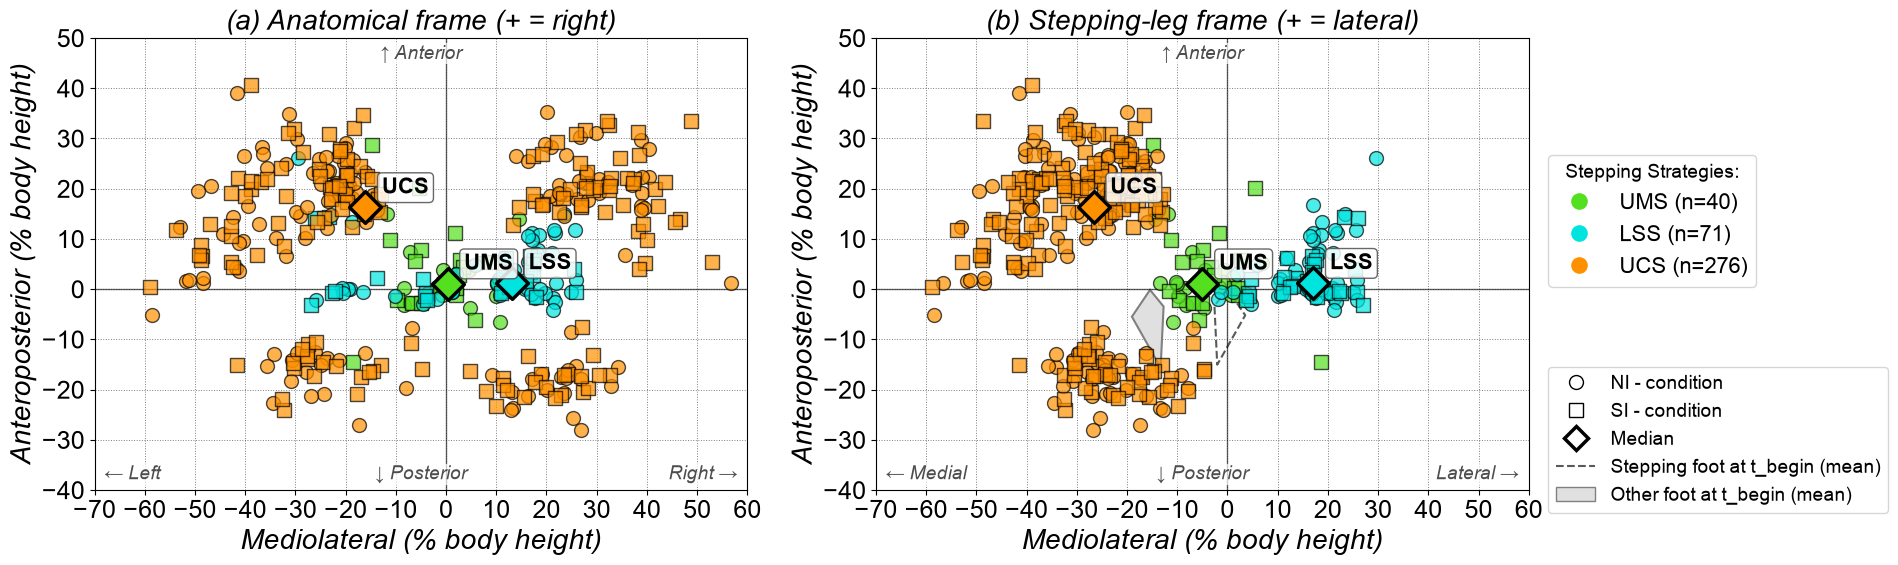

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH + 3, 1.25 * style.FIG_HEIGHT))
# Same limits in both panels: same scale and aligned panels
xlim = style.symmetric_limits(np.r_[sel["ml_pct"], sel["ml_lateral_pct"]], step=10)
ylim = style.symmetric_limits(sel["ap_pct"], step=10)
figures.plot_decomposition(axes[0], sel, frame="anatomical", xlim=xlim, ylim=ylim, show_feet=False)
figures.plot_decomposition(axes[1], sel, frame="lateral", xlim=xlim, ylim=ylim)
style.set_labels(axes[0], title="(a) Anatomical frame (+ = right)")
style.set_labels(axes[1], title="(b) Stepping-leg frame (+ = lateral)")
figures.decomposition_legends(axes[1], sel)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_Decomposition_ML_AP.pdf", bbox_inches="tight")
plt.show()

**Figure 1. End position of the stepping foot after the first recovery step (lateral strategies, n = 387 trials).** Each point is one trial: the displacement of the stepping toe marker between t_begin and t_end, decomposed on the mediolateral (ML, horizontal axis) and anteroposterior (AP, vertical axis, + anterior) axes, in % of body height. The origin is the toe position at t_begin. Colour = Unified strategy (UMS n = 40, LSS n = 71, UCS n = 276). Marker = sensory condition (○ NI, □ SI). Large diamonds = median end position of each strategy. Both panels show the same trials with the same AP values and the same axis limits. Only the sign of the ML component differs.

**(a) Anatomical frame.** + ML = participant's right (`ml_pct`). Left-foot and right-foot steps are not merged, so each strategy forms two clusters mirrored about ML = 0. For example, right-foot LSS land at + ML and left-foot LSS at − ML. Right-foot UCS cross to − ML and left-foot UCS to + ML. Each median mixes the two mirrored clusters and is pulled towards ML = 0, so it does not show a typical step direction.

**(b) Stepping-leg frame.** The ML sign is flipped for left-foot steps (`ml_lateral_pct`). + ML = lateral side of the stepping leg, − ML = medial, towards the other foot. The mirrored clusters of (a) merge into one cluster per strategy, and the medians are those of the summary tables (section 7). Dashed outline = mean initial position of the stepping foot at t_begin. Grey polygon = mean initial position of the other foot at t_begin. Both outlines use the same flipped frame. They are not drawn in (a), where left and right feet lie on opposite sides and a mean outline would not match any real foot position.

## 6. Figure 2: distribution of each component per strategy

Box plots (median, interquartile range, whiskers at 1.5 IQR) with all trials overlaid. ML is shown in the stepping-leg frame.

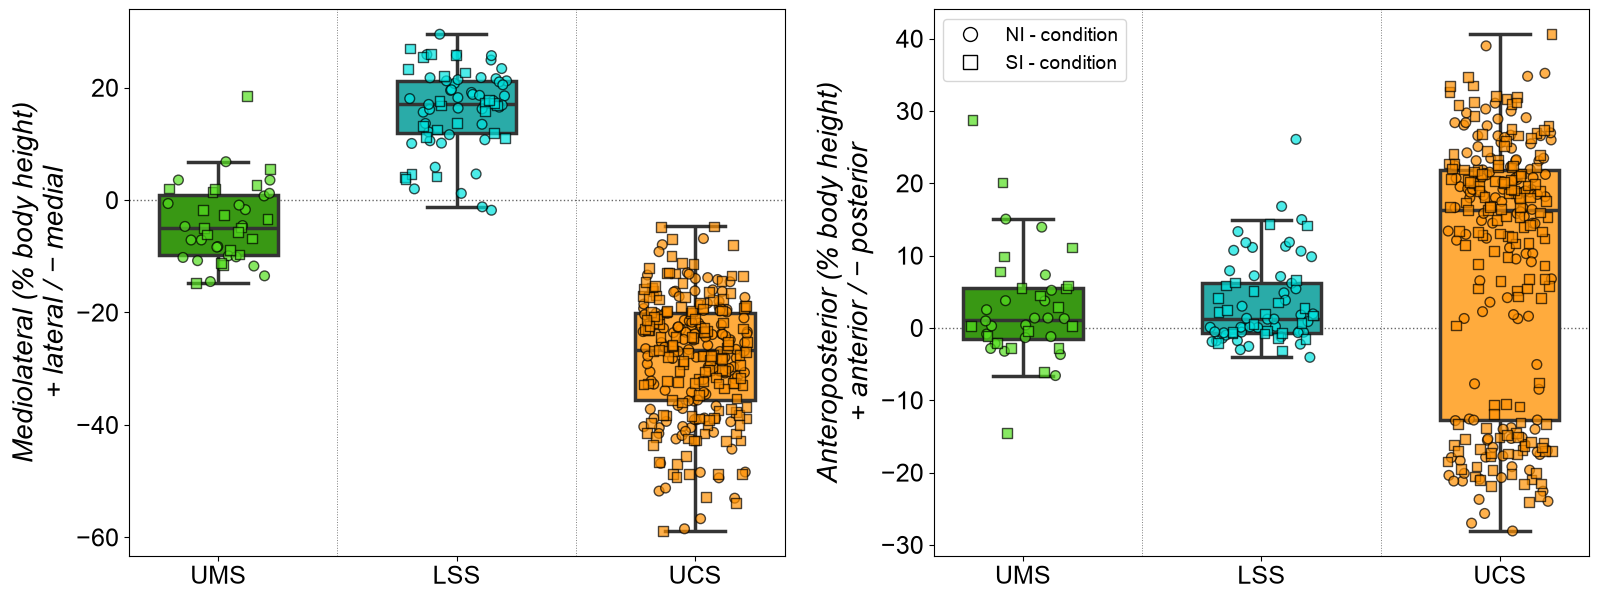

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH, style.FIG_HEIGHT))
figures.plot_component_boxes(axes[0], sel, "ml_lateral_pct", "Mediolateral (% body height)\n+ lateral / − medial")
figures.plot_component_boxes(axes[1], sel, "ap_pct", "Anteroposterior (% body height)\n+ anterior / − posterior")
handles, labels = style.condition_handles()
axes[1].legend(handles, labels, fontsize=style.FONT_SIZE - 6, loc="upper left")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_Components_Boxplots.pdf", bbox_inches="tight")
plt.show()

## 7. Descriptive statistics

In [7]:
def summarise(df, columns, by="strategy", order=style.STRATEGY_ORDER):
    """Median [Q1, Q3] and mean (SD) of columns per group.

    Parameters
    ----------
    df : pandas.DataFrame
        Selected first-step rows.
    columns : dict of str -> str
        {column name: display name}.
    by : str or list of str, optional
        Grouping column(s). Default "strategy".
    order : list, optional
        Order of the first grouping level.

    Returns
    -------
    pandas.DataFrame
        One row per group: n, then "median [Q1, Q3]" and "mean (SD)" for each
        column (values in the unit of the column, here % body height).
    """
    rows = {}
    for key, g in df.groupby(by):
        row = {"n": len(g)}
        for col, name in columns.items():
            q1, med, q3 = g[col].quantile([0.25, 0.5, 0.75])
            row[f"{name} median [Q1, Q3]"] = f"{med:.1f} [{q1:.1f}, {q3:.1f}]"
            row[f"{name} mean (SD)"] = f"{g[col].mean():.1f} ({g[col].std():.1f})"
        rows[key] = row
    out = pd.DataFrame(rows).T
    if isinstance(by, str):
        out = out.loc[[s for s in order if s in out.index]]
    return out


sel["step_length_pct"] = np.hypot(sel["ml_pct"], sel["ap_pct"])
columns = {"ml_lateral_pct": "ML lateral", "ap_pct": "AP", "step_length_pct": "Length"}
summarise(sel, columns)

,n,"ML lateral median [Q1, Q3]",ML lateral mean (SD),"AP median [Q1, Q3]",AP mean (SD),"Length median [Q1, Q3]",Length mean (SD)
UMS,40,"-5.0 [-9.7, 0.8]",-4.2 (6.9),"1.1 [-1.5, 5.5]",2.7 (7.6),"8.3 [4.1, 10.7]",9.2 (6.6)
LSS,71,"17.1 [12.0, 21.2]",16.2 (7.1),"1.2 [-0.7, 6.2]",3.4 (5.8),"18.1 [12.8, 22.0]",17.3 (7.6)
UCS,276,"-26.6 [-35.6, -20.1]",-28.0 (10.7),"16.3 [-12.7, 21.9]",8.9 (17.9),"33.8 [28.4, 41.7]",34.9 (9.0)


Same statistics per sensory condition:

In [8]:
summarise(sel, columns, by=["strategy", "condition"]).reindex(
    [(s, c) for s in style.STRATEGY_ORDER for c in config.CONDITIONS])

n ML lateral median [Q1, Q3] ML lateral mean (SD)  \
UMS NI   21         -7.1 [-10.1, -0.6]           -5.2 (6.1)   
    SI   19           -4.9 [-7.9, 1.7]           -3.2 (7.6)   
LSS NI   47          17.7 [12.8, 21.1]           16.3 (7.2)   
    SI   24          16.8 [11.7, 22.3]           15.9 (7.2)   
UCS NI  133       -25.8 [-34.5, -20.6]         -28.0 (10.4)   
    SI  143       -27.2 [-36.4, -19.7]         -28.1 (11.1)   

        AP median [Q1, Q3] AP mean (SD) Length median [Q1, Q3]  \
UMS NI     1.0 [-1.3, 3.7]    1.7 (5.3)        8.4 [3.8, 10.2]   
    SI     2.8 [-1.6, 6.8]    3.8 (9.5)        8.3 [5.7, 11.4]   
LSS NI     1.2 [-0.6, 7.5]    3.8 (6.4)      19.5 [13.4, 21.8]   
    SI     1.9 [-0.7, 4.3]    2.5 (4.5)      17.3 [12.3, 22.3]   
UCS NI  17.5 [-12.6, 21.9]   9.2 (18.1)      33.3 [29.1, 41.3]   
    SI  15.4 [-13.2, 21.7]   8.6 (17.9)      34.1 [28.0, 42.2]   

       Length mean (SD)  
UMS NI        8.1 (5.3)  
    SI       10.3 (7.9)  
LSS NI       17.7 (7.6)  
    SI       16.6 (7.6)  
UCS NI       35.0 (8.6)  
    SI       34.8 (9.4)

Share of steps per landing quadrant: lateral (ML lateral > 0) vs medial, and anterior (AP > 0) vs posterior. Values in %.

In [9]:
quadrant = pd.DataFrame({
    "lateral (%)": sel.groupby("strategy")["ml_lateral_pct"].apply(lambda v: 100 * (v > 0).mean()),
    "anterior (%)": sel.groupby("strategy")["ap_pct"].apply(lambda v: 100 * (v > 0).mean()),
    "n": sel.groupby("strategy").size(),
}).loc[style.STRATEGY_ORDER]
quadrant

,lateral (%),anterior (%),n
strategy,,,
UMS,27.5,62.5,40
LSS,97.2,63.4,71
UCS,0.0,71.4,276


## 8. Figure 3: UCS end positions, perturbation angle and intensity

The plot is the same as Figure 1 (b): stepping-leg frame, % body height, same scale. It shows the UCS only, zoomed on the medial side. The marker colour shows one descriptor of the perturbation:
- **(a) Estimated perturbation angle** (manuscript §2.3.1.2, Fig. 2.13). The direction of the horizontal CoM velocity at the moment of minimal time to boundary (Ttb), between perturbation onset and t_begin. It uses kinematics only.
  - Like the ML axis, it is expressed in the stepping-leg frame: 0° = forward, −90° = towards the other foot (medial), + = lateral.
  - Column `estimated_angle_lateral_deg`. The column `estimated_angle_deg` keeps the convention of the previous analysis (+ = participant's left); its sign is flipped for right-foot steps.
  - Its colour scale is drawn as a **fan** in the axes of the plot (up = anterior, left = medial, right = lateral): each colour points in the direction of the CoM motion it stands for. The push came from the opposite side.
- **(b) Perturbation intensity.** The peak force of the push sensor, `max(F − F_end)` (N), as `MaxForce` in the previous analysis. The manuscript describes the Low / Medium / High levels by this maximal force (54 ± 12, 68 ± 13 and 88 ± 20 N).

On the files used before, both quantities reproduce `AllQtyDF.csv` exactly (`02_Analysis_Test.ipynb`, §3).

The figure is drawn by `figures.plot_perturbation_descriptors`. Sections 9 and 10 apply the same analysis to the LSS and the UMS.

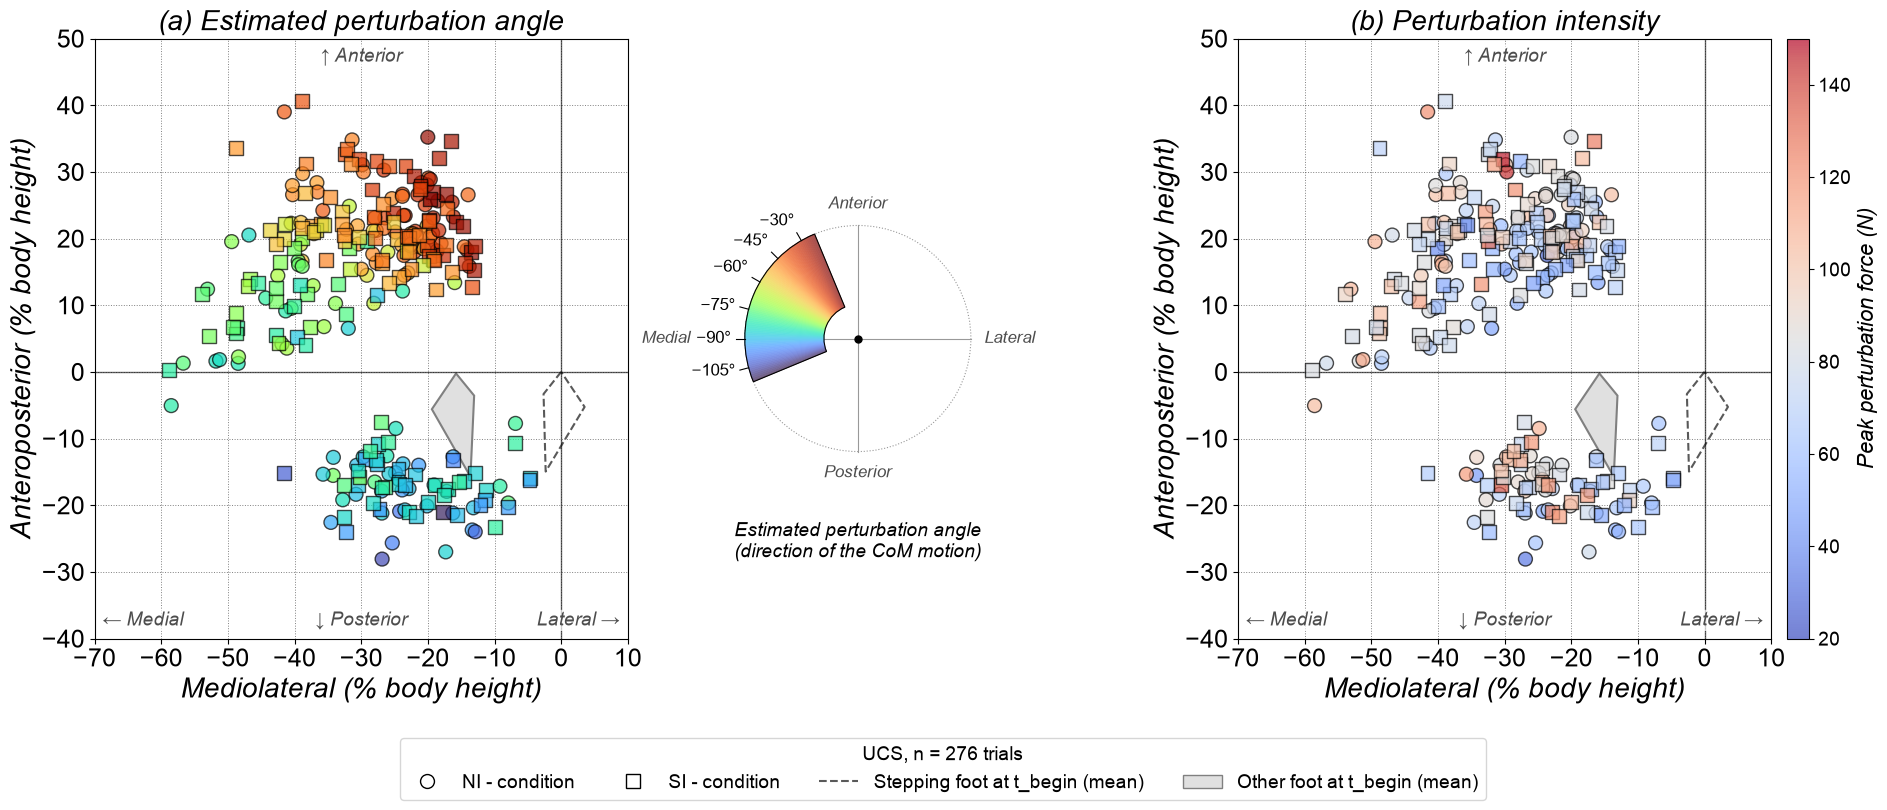

In [10]:
ucs = sel[sel["strategy"] == "UCS"].copy()
fig, axes = figures.plot_perturbation_descriptors(ucs, ylim=ylim)
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_UCS_PerturbationAngle_Intensity.pdf", bbox_inches="tight")
plt.show()

**Figure 3. End position of the stepping foot after a first recovery step labelled UCS, coloured by the perturbation (n = 276 trials).** Each point is one trial: the displacement of the stepping toe marker between t_begin and t_end, in % of body height, in the stepping-leg frame of Figure 1 (b). + ML = lateral side of the stepping leg, − ML = medial, towards the other foot. + AP = anterior. The origin is the toe position at t_begin. Marker = sensory condition (○ NI, □ SI). Dashed outline = mean initial position of the stepping foot at t_begin. Grey polygon = mean initial position of the other foot at t_begin. The axis scale is the same as in Figure 1, but the plot is zoomed on the medial side, where all UCS land.

**(a) Estimated perturbation angle** (turbo colormap): direction of the CoM velocity at the moment of minimal Ttb before t_begin, measured from the forward direction. −90° = purely medial (towards the other foot); values between −90° and 0° have a forward component. The fan between the panels is the colour scale, drawn in the axes of the plot: each colour points in the direction of the CoM motion it stands for (the push came from the opposite side).

**(b) Perturbation intensity** (coolwarm colormap): peak force of the push (N).

Rank correlation (Spearman ρ) between each perturbation descriptor and the step components of the UCS (`perturbation_correlations`, reused for LSS and UMS):

In [11]:
from scipy import stats

DESCRIPTORS = {"estimated_angle_lateral_deg": "Estimated angle", "peak_force": "Peak force"}
COMPONENTS = {"ml_lateral_pct": "ML lateral", "ap_pct": "AP", "step_length_pct": "Length"}


def perturbation_correlations(df):
    """Spearman rank correlation between each perturbation descriptor and each step component.

    Parameters
    ----------
    df : pandas.DataFrame
        Selected first-step rows, usually one strategy.

    Returns
    -------
    pandas.DataFrame
        Rows = descriptors (`DESCRIPTORS`), columns = step components
        (`COMPONENTS`), cells "ρ = +0.85 (p = 1.8e-77)".
    """
    df = df.assign(step_length_pct=np.hypot(df["ml_pct"], df["ap_pct"]))
    return pd.DataFrame({cname: {dname: "ρ = {:+.2f} (p = {:.1e})".format(*stats.spearmanr(df[d], df[c]))
                                 for d, dname in DESCRIPTORS.items()}
                         for c, cname in COMPONENTS.items()})


perturbation_correlations(ucs)

,ML lateral,AP,Length
Estimated angle,ρ = +0.18 (p = 3.4e-03),ρ = +0.85 (p = 1.8e-77),ρ = +0.05 (p = 3.7e-01)
Peak force,ρ = -0.26 (p = 9.7e-06),ρ = +0.17 (p = 6.0e-03),ρ = +0.30 (p = 2.6e-07)


UCS crossing in front of (AP > 0) or behind (AP < 0) the other leg: perturbation descriptors (median [Q1, Q3], mean (SD); deg and N) and instructed push direction. In the stepping-leg frame, the instructed 0° and 180° pushes are lateral (towards the other foot) and the 45° and 135° pushes are diagonal.

In [12]:
INSTRUCTED = {"0": "lateral (0° / 180°)", "180": "lateral (0° / 180°)",
              "45": "diagonal (45° / 135°)", "135": "diagonal (45° / 135°)"}


def ap_side_tables(df, name):
    """Perturbation of the steps ending in front of (AP > 0) or behind (AP < 0) the start position.

    Parameters
    ----------
    df : pandas.DataFrame
        Selected first-step rows, usually one strategy.
    name : str
        Name of the anterior / posterior grouping (e.g. "crossing").

    Returns
    -------
    descriptors : pandas.DataFrame
        Estimated angle (deg) and peak force (N) per group, as `summarise`.
    instructed : pandas.DataFrame
        Number of trials per group and instructed push direction, with totals.
    """
    side = pd.Series(np.where(df["ap_pct"] > 0, "anterior", "posterior"), index=df.index, name=name)
    descriptors = summarise(df.assign(**{name: side}),
                            {"estimated_angle_lateral_deg": "Angle", "peak_force": "Peak force"},
                            by=name, order=["anterior", "posterior"])
    instructed = pd.crosstab(side, df["angle"].map(INSTRUCTED), margins=True, margins_name="Total")
    return descriptors, instructed


for table in ap_side_tables(ucs, "crossing"):
    display(table)

,n,"Angle median [Q1, Q3]",Angle mean (SD),"Peak force median [Q1, Q3]",Peak force mean (SD)
anterior,197,"-48.4 [-66.5, -39.0]",-51.8 (16.7),"79.4 [67.0, 93.0]",80.5 (19.3)
posterior,79,"-87.5 [-91.5, -82.5]",-87.4 (7.4),"77.4 [64.3, 89.7]",79.8 (20.6)


angle,diagonal (45° / 135°),lateral (0° / 180°),Total
crossing,,,
anterior,136,61,197
posterior,0,79,79
Total,136,140,276


## 9. Figure 4: LSS end positions, perturbation angle and intensity

Same analysis as section 8, for the LSS: same figure, descriptors, correlations and tables.
- The LSS land on the lateral side of the stepping leg, so the plot is zoomed on the lateral side. The ML limits also keep the other foot visible.
- In the stepping-leg frame the LSS perturbation angles are **positive**: the CoM moves towards the stepping leg (+90° = lateral), so the fan opens to the right. A perturbation with a forward component therefore has a *smaller* angle (closer to 0°). This is the opposite of UCS and UMS, whose angles are negative.

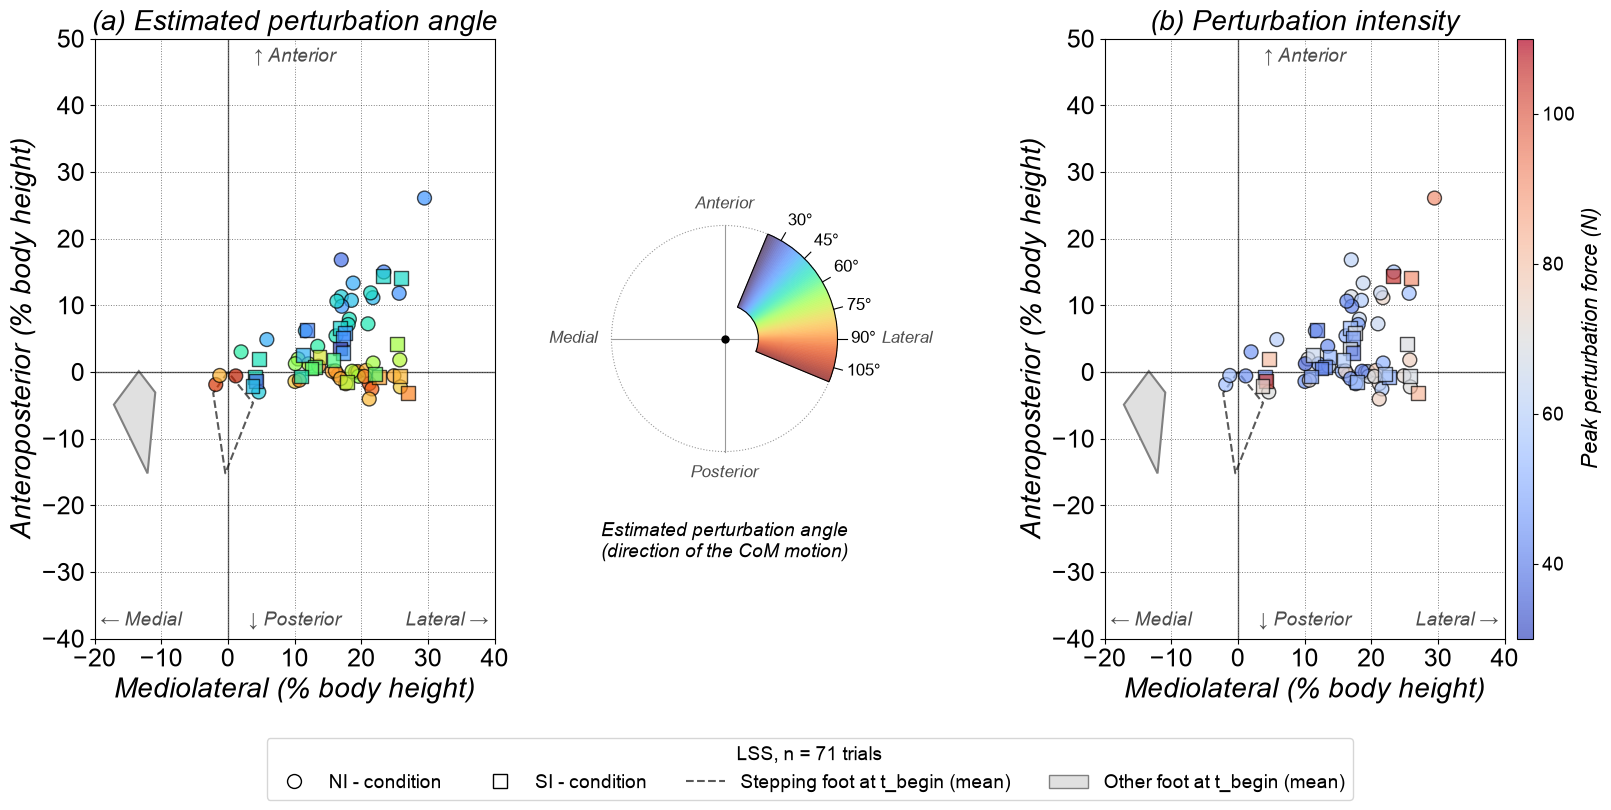

In [13]:
lss = sel[sel["strategy"] == "LSS"].copy()
fig, axes = figures.plot_perturbation_descriptors(lss, ylim=ylim)
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_LSS_PerturbationAngle_Intensity.pdf", bbox_inches="tight")
plt.show()

**Figure 4. End position of the stepping foot after a first recovery step labelled LSS, coloured by the perturbation (n = 71 trials).** Same layout and axis scale as Figure 3, zoomed on the lateral side, where the LSS land. + ML = lateral side of the stepping leg, + AP = anterior. The origin is the toe position at t_begin. Marker = sensory condition (○ NI, □ SI). Dashed outline = mean initial position of the stepping foot at t_begin. Grey polygon = mean initial position of the other foot at t_begin.

**(a) Estimated perturbation angle** (turbo colormap): direction of the CoM motion at the moment of minimal Ttb before t_begin, measured from the forward direction. +90° = purely lateral (towards the stepping leg). Values between 0° and +90° have a forward component, values above +90° a backward component. The fan between the panels is the colour scale, drawn in the axes of the plot (the push came from the opposite side).

**(b) Perturbation intensity** (coolwarm colormap): peak force of the push (N).

The colour ranges cover the LSS values only, so they differ from those of Figure 3.

Spearman ρ between each perturbation descriptor and the step components of the LSS:

In [14]:
perturbation_correlations(lss)

,ML lateral,AP,Length
Estimated angle,ρ = +0.06 (p = 6.4e-01),ρ = -0.68 (p = 8.4e-11),ρ = -0.08 (p = 5.3e-01)
Peak force,ρ = +0.37 (p = 1.4e-03),ρ = -0.05 (p = 6.7e-01),ρ = +0.37 (p = 1.7e-03)


LSS ending in front of (AP > 0) or behind (AP < 0) the start position: perturbation descriptors (median [Q1, Q3], mean (SD); deg and N) and instructed push direction. Unlike the UCS, the AP component of the LSS is not bimodal (section 7): the posterior LSS end at most a few % of body height behind the start. This split therefore separates forward-lateral steps from almost purely sideways steps. For the LSS, the instructed 0° and 180° pushes are sideways, towards the stepping leg.

In [15]:
for table in ap_side_tables(lss, "landing"):
    display(table)

,n,"Angle median [Q1, Q3]",Angle mean (SD),"Peak force median [Q1, Q3]",Peak force mean (SD)
anterior,45,"50.6 [43.2, 66.3]",54.9 (15.3),"58.8 [46.2, 68.1]",59.5 (15.7)
posterior,26,"83.1 [66.7, 89.7]",77.8 (18.6),"67.6 [51.1, 72.5]",63.5 (15.0)


angle,diagonal (45° / 135°),lateral (0° / 180°),Total
landing,,,
anterior,31,14,45
posterior,3,23,26
Total,34,37,71


## 10. Figure 5: UMS end positions, perturbation angle and intensity

Same analysis for the UMS. Like the UCS, the UMS follow perturbations towards the other foot: the angles are negative (medial) and the fan opens to the left. The UMS sample is small (n = 40), so the correlations below are less precise than those of LSS and UCS.

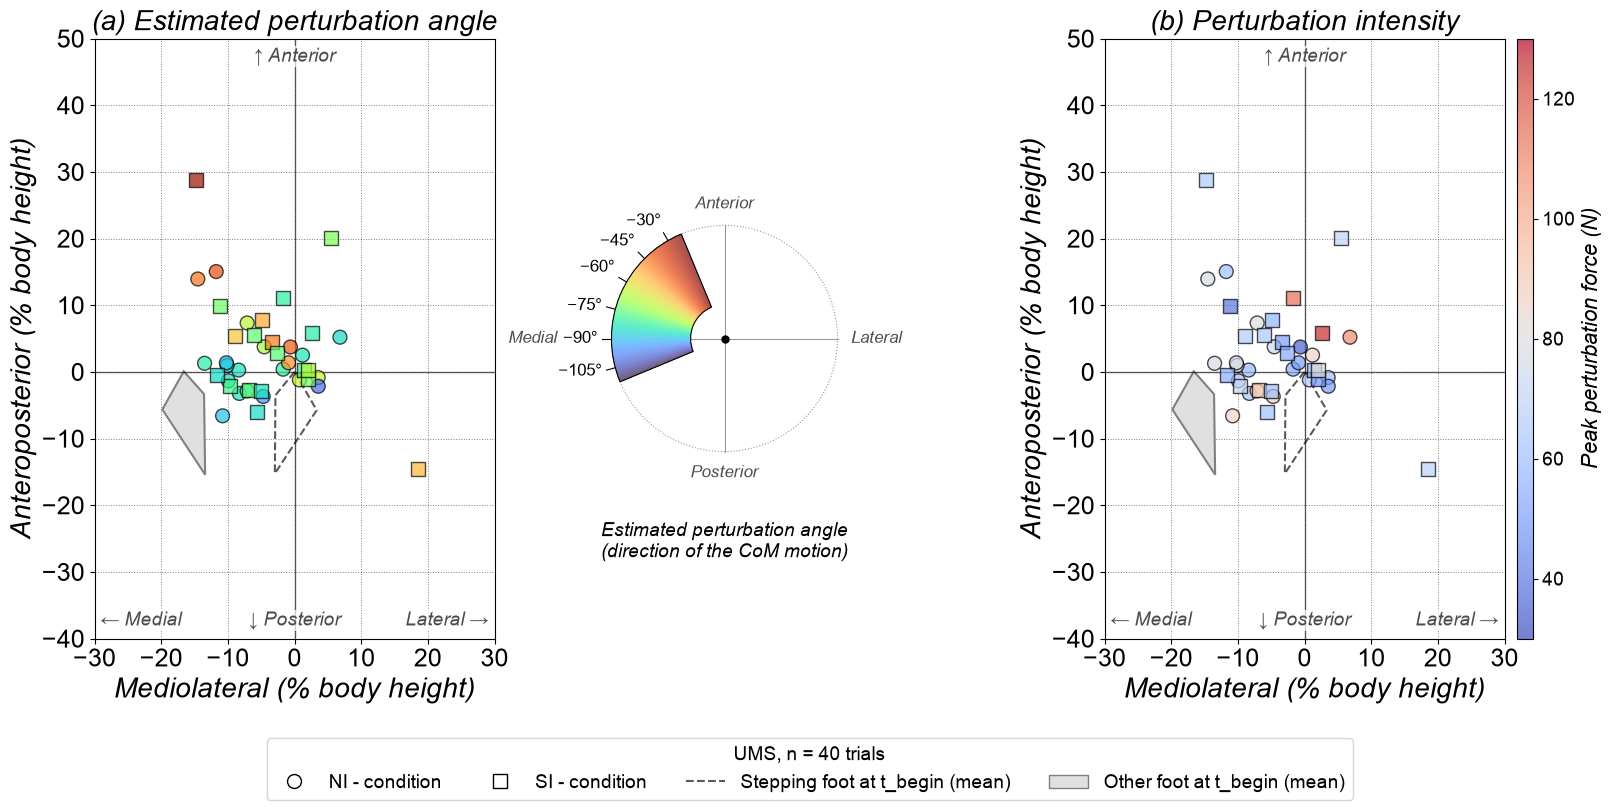

In [16]:
ums = sel[sel["strategy"] == "UMS"].copy()
fig, axes = figures.plot_perturbation_descriptors(ums, ylim=ylim)
fig.savefig(config.FIGURES_DIR / "Fig_FirstStep_UMS_PerturbationAngle_Intensity.pdf", bbox_inches="tight")
plt.show()

**Figure 5. End position of the stepping foot after a first recovery step labelled UMS, coloured by the perturbation (n = 40 trials).** Same layout and axis scale as Figures 3 and 4. The UMS end close to the start position, mostly on the medial side, between the origin and the other foot. Markers, outlines and panels as in Figure 3: (a) estimated perturbation angle, with the fan as colour scale (−90° = purely medial, towards the other foot); (b) peak force of the push (N). The colour ranges cover the UMS values only.

Spearman ρ between each perturbation descriptor and the step components of the UMS:

In [17]:
perturbation_correlations(ums)

,ML lateral,AP,Length
Estimated angle,ρ = +0.05 (p = 7.6e-01),ρ = +0.52 (p = 6.7e-04),ρ = +0.04 (p = 8.0e-01)
Peak force,ρ = -0.05 (p = 7.8e-01),ρ = -0.01 (p = 9.6e-01),ρ = +0.27 (p = 9.8e-02)


UMS ending in front of (AP > 0) or behind (AP < 0) the start position, as for the LSS. The AP values of the UMS are small (section 7), so this split mostly separates slightly forward from slightly backward steps.

In [18]:
for table in ap_side_tables(ums, "landing"):
    display(table)

,n,"Angle median [Q1, Q3]",Angle mean (SD),"Peak force median [Q1, Q3]",Peak force mean (SD)
anterior,25,"-73.4 [-79.9, -49.6]",-66.4 (17.9),"65.6 [55.3, 79.2]",70.4 (22.0)
posterior,15,"-82.8 [-84.6, -73.7]",-79.1 (12.9),"63.4 [60.9, 78.6]",68.0 (14.4)


angle,diagonal (45° / 135°),lateral (0° / 180°),Total
landing,,,
anterior,9,16,25
posterior,3,12,15
Total,12,28,40


## 11. Perturbation and first step: the three lateral strategies side by side

Spearman ρ of sections 8 to 10. **Sign of the angle.** In the stepping-leg frame, the UMS and UCS angles are negative (medial) and the LSS angles are positive (lateral). In all three strategies, a more forward perturbation has an angle closer to 0°: a larger angle for UMS and UCS, a smaller one for LSS. So ρ(angle, AP) > 0 for UMS / UCS and ρ(angle, AP) < 0 for LSS mean the same thing: the more forward the perturbation, the more anterior the step.

In [19]:
comparison = pd.concat({f"{s} (n = {(sel['strategy'] == s).sum()})": perturbation_correlations(sel[sel["strategy"] == s]).stack()
                        for s in style.STRATEGY_ORDER}, axis=1)
comparison.index.names = ["descriptor", "component"]
comparison

UMS (n = 40)             LSS (n = 71)  \
descriptor      component                                                      
Estimated angle ML lateral  ρ = +0.05 (p = 7.6e-01)  ρ = +0.06 (p = 6.4e-01)   
                AP          ρ = +0.52 (p = 6.7e-04)  ρ = -0.68 (p = 8.4e-11)   
                Length      ρ = +0.04 (p = 8.0e-01)  ρ = -0.08 (p = 5.3e-01)   
Peak force      ML lateral  ρ = -0.05 (p = 7.8e-01)  ρ = +0.37 (p = 1.4e-03)   
                AP          ρ = -0.01 (p = 9.6e-01)  ρ = -0.05 (p = 6.7e-01)   
                Length      ρ = +0.27 (p = 9.8e-02)  ρ = +0.37 (p = 1.7e-03)   

                                      UCS (n = 276)  
descriptor      component                            
Estimated angle ML lateral  ρ = +0.18 (p = 3.4e-03)  
                AP          ρ = +0.85 (p = 1.8e-77)  
                Length      ρ = +0.05 (p = 3.7e-01)  
Peak force      ML lateral  ρ = -0.26 (p = 9.7e-06)  
                AP          ρ = +0.17 (p = 6.0e-03)  
                Length      ρ = +0.30 (p = 2.6e-07)

## 12. Observations (this run)

- **LSS.** The loaded foot steps outward: ML lateral median ≈ +17 % body height. The AP component stays small (median ≈ +1 %), so LSS is an almost purely sideways step.
- **UMS.** The unloaded foot mostly moves medially towards the other foot: ML lateral median ≈ −5 %, medial in about 72 % of the trials, with a small AP component. Medial end positions sit between the origin and the initial position of the other foot (panel b). This matches the definition: no crossing, so the foot cannot pass the other foot. The remaining ~28 % land slightly lateral (mostly < +7 %). These UMS are named by the CoM path (it entered the other foot first), not by the foot direction.
- **UCS.** The foot travels medially past the other foot (median ≈ −27 %). The AP component is **bimodal**: about 71 % of the crossovers go in front of the stance leg (AP ≈ +15 to +30 %) and 29 % behind it (AP ≈ −10 to −25 %). Summary statistics of AP for UCS (mean, median) therefore hide two distinct behaviours.
- **UCS and the perturbation (Figure 3).** The perturbation angle decides where the crossover goes:
  - AP increases with the estimated angle (Spearman ρ = +0.85).
  - Anterior crossovers follow perturbations with a forward component (angle median −48°, IQR −67° to −39°).
  - Posterior crossovers follow almost purely medial perturbations (median −88°, all between −111° and −72°). All 79 come from the instructed lateral pushes (0° / 180°), none from the diagonal pushes (45° / 135°).
  - The intensity is only weakly related to the step: stronger pushes give slightly longer (ρ = +0.30) and more medial (ρ = −0.26) crossovers. Anterior and posterior crossovers have the same peak force (median 79 vs 77 N).
- **LSS and the perturbation (Figure 4).** The angles are lateral (median +59°, range +30° to +105°): the CoM moves towards the stepping leg.
  - The angle is strongly related to the AP component, as for UCS: ρ = −0.68 (a smaller LSS angle = a more forward perturbation). It is not related to the ML component (ρ = +0.06).
  - Anterior LSS follow forward-lateral perturbations (angle median +51°, IQR +43° to +66°): 31 of the 34 diagonal pushes give an anterior LSS.
  - Posterior LSS follow almost purely lateral perturbations (median +83°) and come mostly from the sideways pushes (23 of 26). They end at most 4.1 % behind the start: they are sideways steps, not backward steps.
  - Stronger pushes give longer and more lateral steps (ρ = +0.37 for both length and ML lateral), with no effect on AP (ρ = −0.05).
- **UMS and the perturbation (Figure 5).** The angles are medial (median −76°, range −101° to −27°), as for UCS.
  - AP increases with the angle (ρ = +0.52, p < 0.001), more weakly than for UCS. Anterior UMS follow perturbations with a larger forward component (median −73°) than posterior UMS (median −83°). Both groups end close to the start (AP median +4.5 % and −2.8 %).
  - No relation with the intensity (|ρ| ≤ 0.05 for ML lateral and AP; ρ = +0.27 with length, p = 0.10). With n = 40, a weak effect cannot be excluded.
- **Across the three strategies (section 11).** In all three lateral strategies, the forward component of the perturbation sets the AP component of the first step. The relation is strongest for UCS (|ρ| = 0.85), then LSS (0.68) and UMS (0.52). The intensity relates moderately to the step size (length: ρ = +0.30 for UCS, +0.37 for LSS) and at most weakly to its AP direction (|ρ| ≤ 0.17).
- In the anatomical frame (panel a) the clusters are mirrored left/right according to the stepping foot. The stepping-leg frame (panel b) pools both sides.

## 13. Limitations

- **Lab axes as ML/AP axes.** The participant's heading at perturbation onset differs from the lab axes by at most 8.5° (feet) in this dataset. The resulting error on the components is small compared with the spread within each strategy (`02_Analysis_Test.ipynb`, section 5).
- **Open data vs the files used before.** In 26 trials the open data contain an earlier, longer version of the recording than the files used in the previous analysis. For the strategies studied here, only one UCS trial is affected (S15 SI PM0_2, detected as a leg abduction in the open data).
- **Small UMS sample.** UMS is the rarest lateral strategy (n = 40). Its statistics are less precise than those of LSS and UCS, including the correlations with the perturbation (Figure 5).
- **Estimated perturbation angle.** It is the direction of the CoM motion at minimal Ttb, not a measured push direction. In the manuscript it differs from the ground-truth angle (CoM velocity at peak force) by 7° on average for stepping trials (appendix Fig. A.1).
- **Pooling sides.** The stepping-leg frame pools left-foot and right-foot steps, which assumes left/right symmetry. Panel (a) keeps them separate.